<a href="https://colab.research.google.com/github/sabbirpuspo/breast-skin-brain-lesion-segmentation/blob/main/Breast_Skin_Brain_Lesion_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q -U kagglehub pandas pillow matplotlib scikit-learn

import kagglehub
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

DATASETS = {
    "busi": "aryashah2k/breast-ultrasound-images-dataset",
    "isic2016": "mahmudulhasantasin/isic-2016-original-dataset",
    "lgg": "mateuszbuda/lgg-mri-segmentation",
}

# Start with BUSI.
# Later choose "isic2016" or "lgg".
DATASET = "busi"

data_root = Path(
    kagglehub.dataset_download(DATASETS[DATASET])
)

print("Selected dataset:", DATASET)
print("Kaggle location:", data_root)
print("Dataset directory exists:", data_root.is_dir())

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 67.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 68.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 68.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 69.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
Using Colab cache for faster access to the 'breast-ultrasound-images

In [2]:
from collections import Counter

all_files = sorted(
    p for p in data_root.rglob("*")
    if p.is_file()
)

print("Total files:", len(all_files))

print("\nFile types:")
print(Counter(p.suffix.lower() for p in all_files))

print("\nFirst 25 files:")
for p in all_files[:25]:
    print(p.relative_to(data_root))

Total files: 1578

File types:
Counter({'.png': 1578})

First 25 files:
Dataset_BUSI_with_GT/benign/benign (1).png
Dataset_BUSI_with_GT/benign/benign (1)_mask.png
Dataset_BUSI_with_GT/benign/benign (10).png
Dataset_BUSI_with_GT/benign/benign (10)_mask.png
Dataset_BUSI_with_GT/benign/benign (100).png
Dataset_BUSI_with_GT/benign/benign (100)_mask.png
Dataset_BUSI_with_GT/benign/benign (100)_mask_1.png
Dataset_BUSI_with_GT/benign/benign (101).png
Dataset_BUSI_with_GT/benign/benign (101)_mask.png
Dataset_BUSI_with_GT/benign/benign (102).png
Dataset_BUSI_with_GT/benign/benign (102)_mask.png
Dataset_BUSI_with_GT/benign/benign (103).png
Dataset_BUSI_with_GT/benign/benign (103)_mask.png
Dataset_BUSI_with_GT/benign/benign (104).png
Dataset_BUSI_with_GT/benign/benign (104)_mask.png
Dataset_BUSI_with_GT/benign/benign (105).png
Dataset_BUSI_with_GT/benign/benign (105)_mask.png
Dataset_BUSI_with_GT/benign/benign (106).png
Dataset_BUSI_with_GT/benign/benign (106)_mask.png
Dataset_BUSI_with_GT/benign

In [3]:
import re
from collections import defaultdict

IMAGE_TYPES = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

def build_records(root, dataset):

    files = sorted(
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_TYPES
    )

    records = []

    if dataset == "busi":

        categories = {"benign", "malignant", "normal"}

        def category(p):
            return next(
                (x.lower() for x in reversed(p.parent.parts)
                 if x.lower() in categories),
                None
            )

        mask_map = defaultdict(list)

        for p in files:
            if category(p) and "_mask" in p.stem.lower():
                key = (
                    p.parent,
                    p.stem.lower().split("_mask")[0]
                )
                mask_map[key].append(p)

        for p in files:

            label = category(p)

            if label and "_mask" not in p.stem.lower():

                masks = mask_map.get(
                    (p.parent, p.stem.lower()), []
                )

                if label != "normal" and not masks:
                    raise ValueError(
                        f"Missing BUSI mask: {p}"
                    )

                records.append({
                    "image": p,
                    "masks": masks,
                    "group": f"{label}:{p.stem}",
                    "label": label,
                    "partition": "unspecified"
                })

    elif dataset == "isic2016":

        image_map = {}
        mask_map = {}

        for p in files:

            if (
                p.suffix.lower() in {".jpg", ".jpeg"}
                and re.fullmatch(
                    r"ISIC_\d+", p.stem, flags=re.I
                )
            ):
                key = p.stem.upper()

                if key in image_map:
                    raise ValueError(
                        f"Duplicate ISIC image: {key}"
                    )

                image_map[key] = p

            elif (
                p.suffix.lower() == ".png"
                and re.fullmatch(
                    r"ISIC_\d+_segmentation",
                    p.stem,
                    flags=re.I
                )
            ):
                key = p.stem[:-len("_segmentation")].upper()

                if key in mask_map:
                    raise ValueError(
                        f"Duplicate ISIC mask: {key}"
                    )

                mask_map[key] = p

        for key, image in sorted(image_map.items()):

            if key not in mask_map:
                raise ValueError(
                    f"Missing ISIC mask: {key}"
                )

            parent = str(image.parent).lower()

            partition = (
                "test" if "test" in parent
                else "train" if "train" in parent
                else "unknown"
            )

            records.append({
                "image": image,
                "masks": [mask_map[key]],
                "group": key,
                "label": "lesion",
                "partition": partition
            })

    elif dataset == "lgg":

        for p in files:

            if p.suffix.lower() not in {".tif", ".tiff"}:
                continue

            if p.stem.lower().endswith("_mask"):
                continue

            mask = p.with_name(
                p.stem + "_mask" + p.suffix
            )

            if not mask.is_file():
                raise ValueError(
                    f"Missing LGG mask: {p}"
                )

            records.append({
                "image": p,
                "masks": [mask],
                "group": p.parent.name,
                "label": "lgg",
                "partition": "unspecified"
            })

    else:
        raise ValueError(f"Unknown dataset: {dataset}")

    if not records:
        raise ValueError(
            "No image-mask pairs found. "
            "Inspect the dataset folder structure."
        )

    return records


records = build_records(data_root, DATASET)

print("Matched images:", len(records))
print("First record:", records[0])

Matched images: 780
First record: {'image': PosixPath('/kaggle/input/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (1).png'), 'masks': [PosixPath('/kaggle/input/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (1)_mask.png')], 'group': 'benign:benign (1)', 'label': 'benign', 'partition': 'unspecified'}


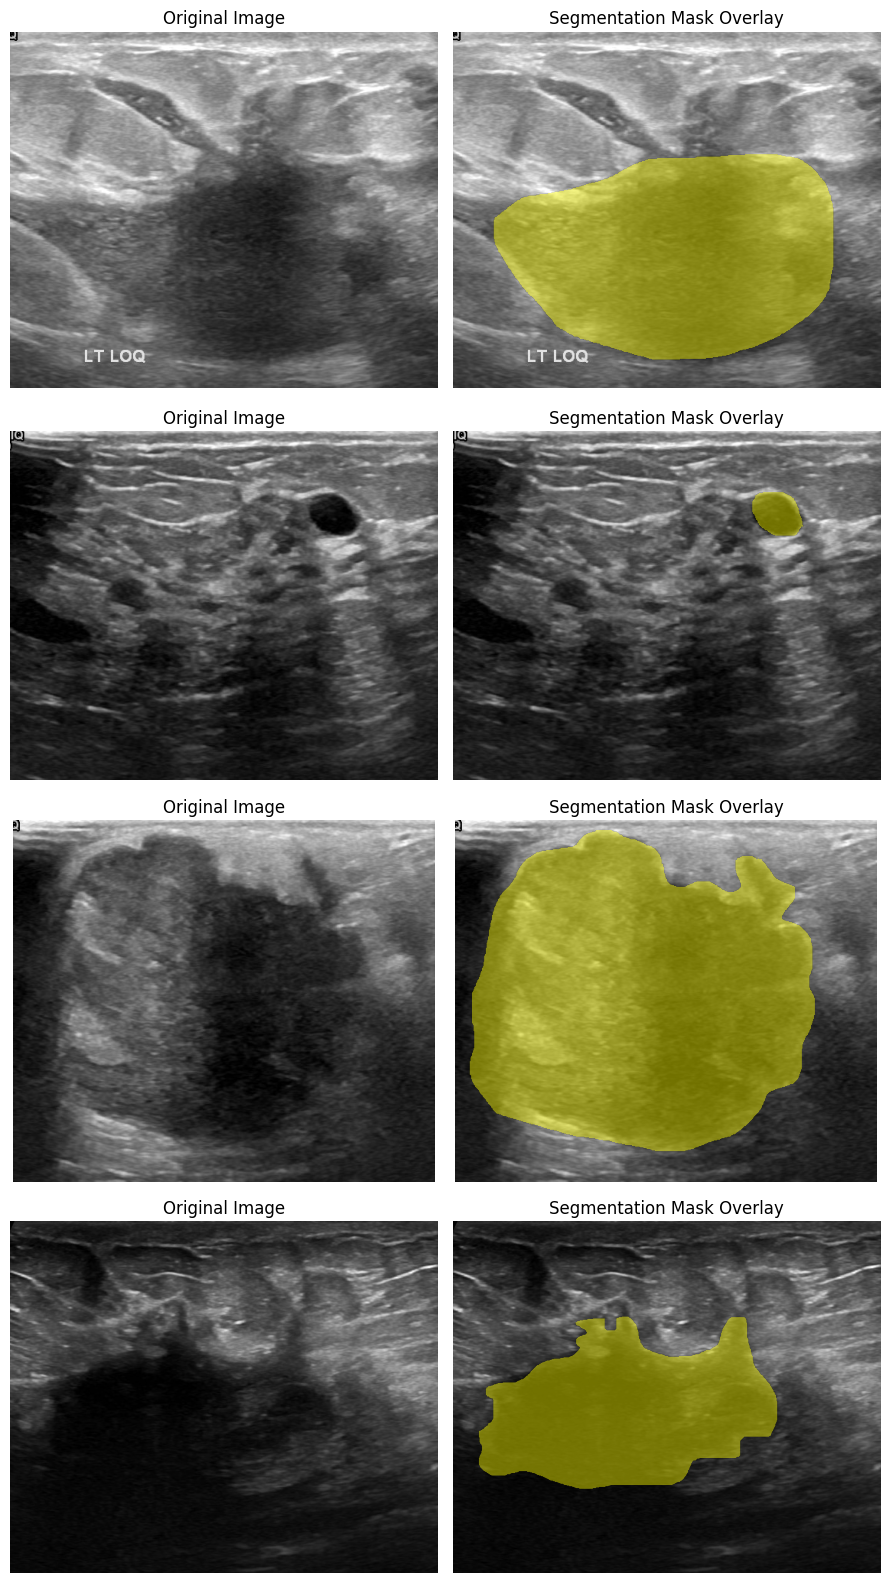

In [4]:
from PIL import Image

def load_image_and_mask(record):

    image = np.asarray(
        Image.open(record["image"]).convert("RGB")
    )

    mask = np.zeros(image.shape[:2], dtype=bool)

    for path in record["masks"]:

        current = np.asarray(
            Image.open(path).convert("L")
        )

        if current.shape != mask.shape:
            raise ValueError(
                f"Image-mask size mismatch: {path}"
            )

        mask |= current > 127

    return image, mask


rng = np.random.default_rng(42)

selected = rng.choice(
    len(records),
    size=min(4, len(records)),
    replace=False
)

fig, axes = plt.subplots(
    len(selected), 2,
    figsize=(9, 4 * len(selected)),
    squeeze=False
)

for row, index in enumerate(selected):

    record = records[int(index)]
    image, mask = load_image_and_mask(record)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title("Original Image")

    axes[row, 1].imshow(image)

    overlay = np.ma.masked_where(~mask, mask)
    axes[row, 1].imshow(
        overlay,
        cmap="autumn",
        alpha=0.45,
        vmin=0,
        vmax=1
    )

    axes[row, 1].set_title("Segmentation Mask Overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit
)

SEED = 42
indices = np.arange(len(records))

if DATASET == "busi":

    labels = np.array([r["label"] for r in records])

    train, remaining = train_test_split(
        indices,
        test_size=0.30,
        stratify=labels,
        random_state=SEED
    )

    val, test = train_test_split(
        remaining,
        test_size=0.50,
        stratify=labels[remaining],
        random_state=SEED
    )

elif DATASET == "isic2016":

    partitions = np.array([
        r["partition"] for r in records
    ])

    if "unknown" in partitions:
        raise ValueError(
            "Cannot verify the official ISIC train/test "
            "partition from these file paths."
        )

    official_train = indices[partitions == "train"]
    test = indices[partitions == "test"]

    if len(official_train) == 0:
        raise ValueError("No official ISIC training images found.")

    train, val = train_test_split(
        official_train,
        test_size=0.20,
        random_state=SEED
    )

    if len(test) == 0:
        print(
            "Warning: Official test masks are not available "
            "in this mirror. Do not report test results."
        )

elif DATASET == "lgg":

    groups = np.array([r["group"] for r in records])

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.30,
        random_state=SEED
    )

    train_pos, other_pos = next(
        splitter.split(indices, groups=groups)
    )

    train = indices[train_pos]
    remaining = indices[other_pos]

    splitter2 = GroupShuffleSplit(
        n_splits=1,
        test_size=0.50,
        random_state=SEED
    )

    val_pos, test_pos = next(
        splitter2.split(
            remaining,
            groups=groups[remaining]
        )
    )

    val = remaining[val_pos]
    test = remaining[test_pos]

    assert set(groups[train]).isdisjoint(groups[val])
    assert set(groups[train]).isdisjoint(groups[test])
    assert set(groups[val]).isdisjoint(groups[test])


for name, subset in [
    ("train", train),
    ("val", val),
    ("test", test)
]:
    for index in subset:
        records[int(index)]["split"] = name

print("Training images:", len(train))
print("Validation images:", len(val))
print("Test images:", len(test))

Training images: 546
Validation images: 117
Test images: 117


In [6]:
import json

manifest = []

for record in records:

    manifest.append({
        "dataset": DATASET,
        "image": str(
            record["image"].relative_to(data_root)
        ),
        "masks": json.dumps([
            str(p.relative_to(data_root))
            for p in record["masks"]
        ]),
        "group": record["group"],
        "split": record["split"]
    })

manifest_path = Path(
    f"/content/{DATASET}_split_manifest.csv"
)

pd.DataFrame(manifest).to_csv(
    manifest_path,
    index=False
)

print("Manifest saved:", manifest_path)

Manifest saved: /content/busi_split_manifest.csv
